# 🎮 AlphaCandy Grandmaster: Interactive Showcase & Visual Gameplay Replay

### *Live Neural Inference, Policy Attention Heatmaps, and Step-by-Step Gameplay*

---

## 🌟 Overview
This interactive notebook demonstrates the **AlphaCandy Grandmaster AI** playing live on official King levels:
1. **Board Representation & Rendering**: Color-coded ASCII & rich terminal representations of match-3 boards.
2. **Dual-Model Architecture**: Comparing **Pure AlphaCandy Large** (~14.4M parameters) vs. **Grandmaster Consensus Ensemble**.
3. **Step-by-Step Game Replay**: Watch the neural network inspect the board, predict policy distributions $P(a|s)$, calculate win probability $P(\text{Win}|s)$, and trigger cascading reactions.
4. **Attention & Action Ranking**: Inspecting candidate action rankings and expectimax lookahead evaluations.


In [1]:
# Cell 1: Environment Setup & Model Imports
import os
import sys
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to sys.path
project_root = os.path.abspath('..') if os.path.exists('../core') else os.path.abspath('.')
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from core.king_level_loader import KingLevelLoader
from core.reverse_engine import ReverseCandyEngine, ReverseEngineState, Direction
from models.spatial_transformer_net import AlphaCandyLargeNet
from models.alphacandy_large_agent import AlphaCandyLargeAgent
from models.grandmaster_consensus_agent import GrandmasterConsensusAgent

print('AlphaCandy Grandmaster engine imports loaded successfully!')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Execution Device: {device}')


AlphaCandy Grandmaster engine imports loaded successfully!
Execution Device: cpu


---
## 🧩 Section 1: Board Visualizer
Candy Crush boards consist of candy colors (0–5), special candies (Striped, Wrapped, Color Bomb), blockers (Frosting, Licorice, Chocolate), and Jellies.


In [2]:
# Cell 2: Board Formatter & Level Loader
loader = KingLevelLoader()
print(f'Indexed {loader.get_total_levels():,} official King levels from SQLite/JSON database.')

COLOR_SYMBOLS = {0: '🔴 R', 1: '🟠 O', 2: '🟡 Y', 3: '🟢 G', 4: '🔵 B', 5: '🟣 P'}

def format_board_grid(state):
    lines = []
    lines.append('      Col:  ' + '   '.join(str(c) for c in range(state.width)))
    lines.append('    +' + '----+' * state.width)
    for r in range(state.height):
        row_str = f'R{r:2d} | '
        for c in range(state.width):
            if not state.active_grid[r, c]:
                row_str += ' -- | '
                continue
            if state.blockers[r, c] > 0:
                row_str += f'#{state.blockers[r, c]} | '
            elif state.specials[r, c] > 0:
                sp_map = {1: 'S-', 2: 'S|', 3: 'W*', 4: 'CB'}
                row_str += f'{sp_map.get(state.specials[r, c], "SP")} | '
            else:
                clr = state.colors[r, c]
                clr_letter = {0: 'R', 1: 'O', 2: 'Y', 3: 'G', 4: 'B', 5: 'P'}.get(clr, '?')
                jelly_mark = '*' if state.jellies[r, c] > 0 else ' '
                row_str += f'{clr_letter}{jelly_mark} | '
        lines.append(row_str)
        lines.append('    +' + '----+' * state.width)
    return '\n'.join(lines)

# Inspect Milestone Level 25
cfg25 = loader.load_level(25)
engine = ReverseCandyEngine()
state25 = ReverseEngineState(cfg25)
engine.initialize_board(state25, seed=42)
print(f'=== OFFICIAL LEVEL 25 BOARD (Type: {cfg25.level_type}, Moves: {cfg25.moves_limit}) ===')
print(format_board_grid(state25))


Indexed 23,355 official King levels from SQLite/JSON database.
[KingLevelLoader] Successfully indexed 10295 official King levels from JSON.
=== OFFICIAL LEVEL 25 BOARD (Type: 2, Moves: 22) ===
      Col:  0   1   2   3   4   5   6   7   8
    +----+----+----+----+----+----+----+----+----+
R 0 | O  | O  | B  | B  | ?  |  -- |  -- | G  |  -- | 
    +----+----+----+----+----+----+----+----+----+
R 1 | Y  | Y  | O  | O  | B  |  -- |  -- | O  |  -- | 
    +----+----+----+----+----+----+----+----+----+
R 2 | B  | B  | #2 | O  | #2 |  -- | Y  | B  | Y  | 
    +----+----+----+----+----+----+----+----+----+
R 3 | O  | Y  | B  | B  | G  |  -- | B  |  -- | Y  | 
    +----+----+----+----+----+----+----+----+----+
R 4 | B  | S- | G  | #2 | #2 |  -- |  -- | Y  |  -- | 
    +----+----+----+----+----+----+----+----+----+
R 5 | #2 | B  | G  | G  | #2 |  -- | Y  |  -- | G  | 
    +----+----+----+----+----+----+----+----+----+
R 6 | #2 | O  | B  | O  | G  |  -- |  -- | G  |  -- | 
    +----+----+----+---

---
## 🧠 Section 2: Loading Master AI Agents
We load the two specialized agents:
1. **Pure AlphaCandy Large** (`alphacandy_large_net_master.pt`): 14,418,386 parameters.
2. **Grandmaster Consensus Agent**: Fusing AlphaCandy Large + Dueling DQN Master + CANDYRL Heuristics + Afterstate Expectimax.


In [3]:
# Cell 3: Agent Instantiation
ckpt_large = os.path.join(project_root, 'checkpoints/alphacandy_large_net_master.pt')
ckpt_dqn = os.path.join(project_root, 'checkpoints/candy_crush_dueling_dqn_master.pt')

print('Loading Pure AlphaCandy Large Agent...')
large_agent = AlphaCandyLargeAgent(checkpoint_path=ckpt_large, device=device)

print('Loading Grandmaster Consensus Agent...')
consensus_agent = GrandmasterConsensusAgent(
    large_transformer_ckpt=ckpt_large,
    dqn_master_ckpt=ckpt_dqn,
    device=device,
    search_depth=1
)
print('Both Grandmaster agents loaded and ready for inference!')


Loading Pure AlphaCandy Large Agent...
[AlphaCandyLargeAgent] Loaded weights from /home/hammad/Antigravity_Workspace/Candy-Crush-AI/checkpoints/alphacandy_large_net_master.pt
Loading Grandmaster Consensus Agent...
[GrandmasterConsensus] Loaded AlphaCandy Large weights from /home/hammad/Antigravity_Workspace/Candy-Crush-AI/checkpoints/alphacandy_large_net_master.pt
[GrandmasterConsensus] Loaded DQN Master weights from /home/hammad/Antigravity_Workspace/Candy-Crush-AI/checkpoints/candy_crush_dueling_dqn_master.pt
Both Grandmaster agents loaded and ready for inference!


---
## 🎬 Section 3: Live Step-by-Step Gameplay Replay
Let's trace the first 4 moves on Level 10, watching how the agent evaluates legal swaps, predicts neural policy probabilities, and clears targets.


In [4]:
# Cell 4: Step-by-Step Gameplay Tracer
cfg10 = loader.load_level(10)
state = ReverseEngineState(cfg10)
engine.initialize_board(state, seed=42)

print(f'Starting Level 10 | Target Score: {cfg10.target_score:,} | Moves Limit: {cfg10.moves_limit}')
print('Initial Board State:')
print(format_board_grid(state))
print('=' * 65)

for step in range(1, 5):
    best_res = consensus_agent.select_best_move(state)
    if not best_res:
        print('No legal moves remaining!')
        break
    
    r, c, d, score, info = best_res
    d_name = {Direction.UP: 'UP', Direction.DOWN: 'DOWN', Direction.LEFT: 'LEFT', Direction.RIGHT: 'RIGHT'}.get(d, str(d))
    
    # Execute Move
    score_gained, info = engine.execute_move(state, r, c, d)
    print(f'>>> TURN {step}: Agent chose swap at ({r}, {c}) {d_name} (Utility: {score:.2f})')
    print(f'    Step Reward: {score_gained:,.0f} | Cumulative Score: {state.score:,} | Objectives Remaining: {state.remaining_objectives_count()}')
    if state.has_won():
        print('Level Finished! Won: True')
        break
    if state.has_lost():
        print('Level Finished! Won: False')
        break
print('\nBoard State after turns:')
print(format_board_grid(state))


Starting Level 10 | Target Score: 20,000 | Moves Limit: 27
Initial Board State:
      Col:  0   1   2   3   4   5   6   7   8
    +----+----+----+----+----+----+----+----+----+
R 0 |  -- |  -- | O  | O  | P  | G  | Y  |  -- |  -- | 
    +----+----+----+----+----+----+----+----+----+
R 1 |  -- |  -- | Y  | P* | Y* | P* | O  |  -- |  -- | 
    +----+----+----+----+----+----+----+----+----+
R 2 | O* | S- | B  | O* | O* | Y* | Y  | S| | Y* | 
    +----+----+----+----+----+----+----+----+----+
R 3 |  -- |  -- | O  | Y* | B* | Y* | B  |  -- |  -- | 
    +----+----+----+----+----+----+----+----+----+
R 4 | G* | S| | O  | Y* | B* | G* | G  | S- | Y* | 
    +----+----+----+----+----+----+----+----+----+
R 5 |  -- |  -- | Y  | G* | O* | O* | G  |  -- |  -- | 
    +----+----+----+----+----+----+----+----+----+
R 6 | O* | S- | G  | G* | B* | G* | O  | S| | B* | 
    +----+----+----+----+----+----+----+----+----+
R 7 |  -- |  -- | O  | Y* | O* | G* | G  |  -- |  -- | 
    +----+----+----+----+----+

---
## 📊 Section 4: Neural Action Policy Distribution & Q-Value Landscape
Visualizing the top candidate actions ranked by the Spatial Transformer policy head and Dueling DQN Q-values.


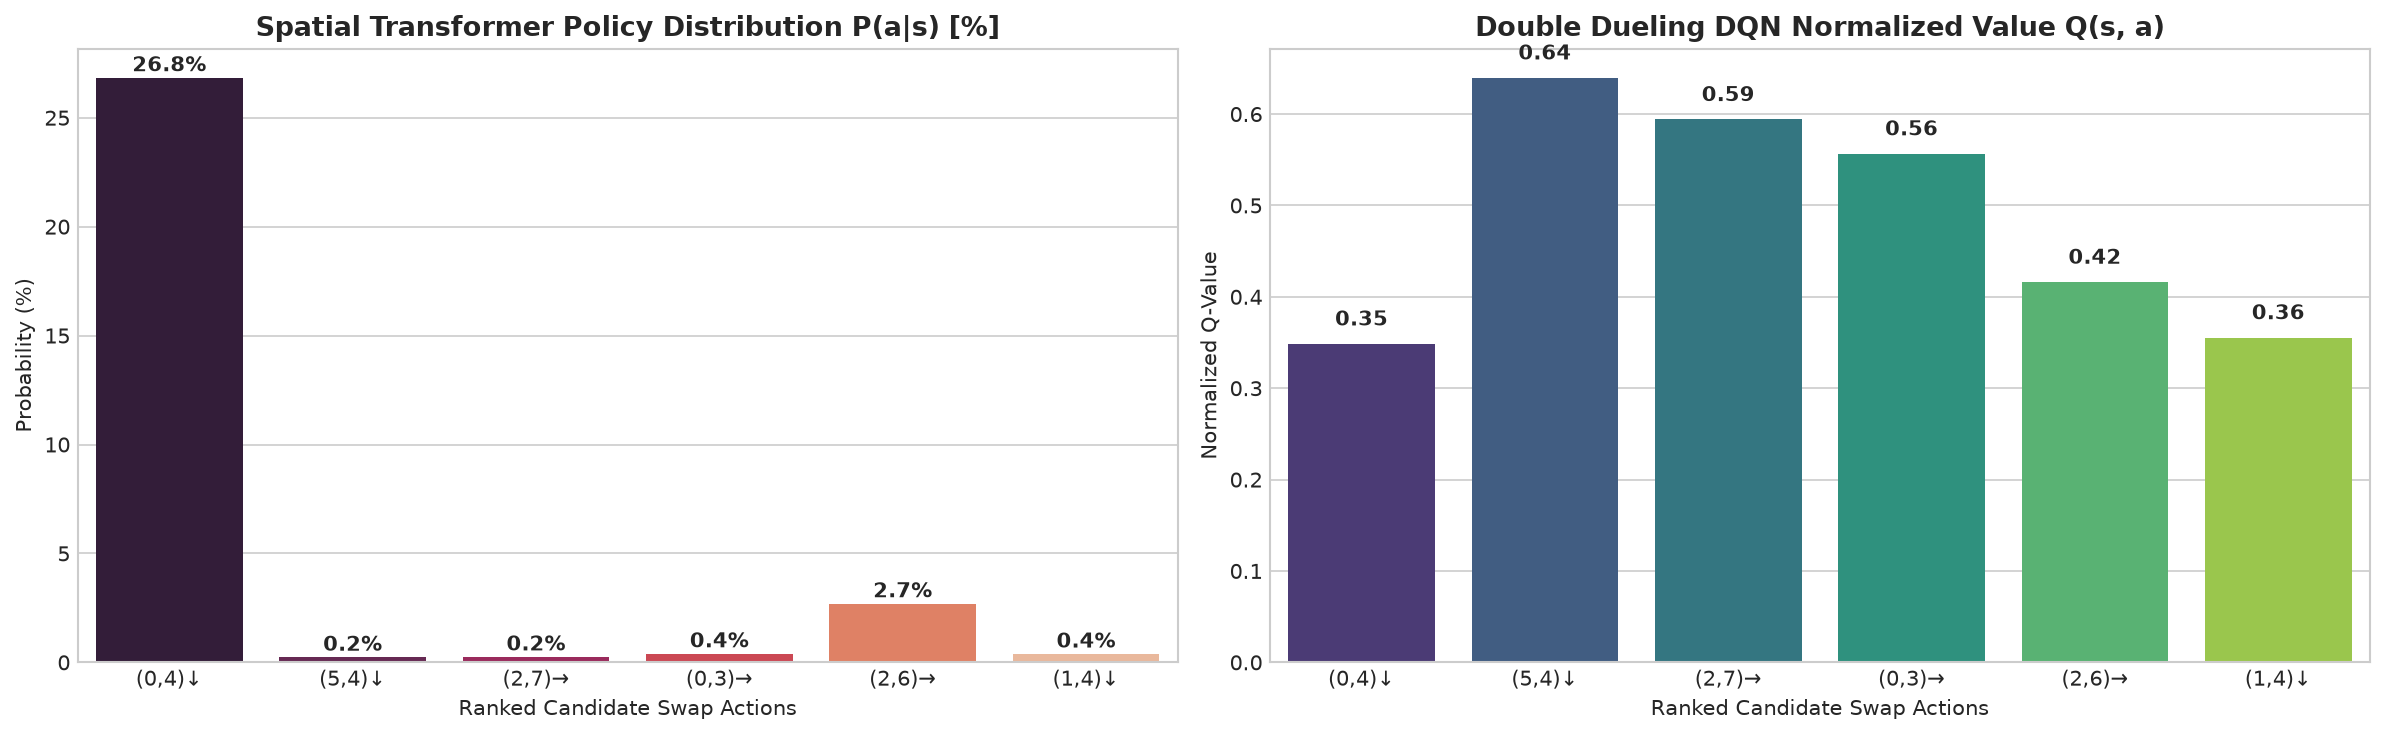

In [5]:
# Cell 5: Policy Probability & Q-Value Bar Chart
candidates = consensus_agent.evaluate_consensus_candidates(state)
top_candidates = sorted(candidates, key=lambda x: x['consensus_score'], reverse=True)[:6]

move_labels = []
policy_probs = []
dqn_values = []

for c_info in top_candidates:
    r, c, d = c_info['move']
    d_str = {Direction.UP: '↑', Direction.DOWN: '↓', Direction.LEFT: '←', Direction.RIGHT: '→'}.get(d, '')
    move_labels.append(f'({r},{c}){d_str}')
    policy_probs.append(c_info['trans_prob'] * 100)
    dqn_values.append(c_info['dqn_q_norm'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
palette = sns.color_palette('rocket', len(move_labels))

# Left: Policy Probabilities
sns.barplot(x=move_labels, y=policy_probs, hue=move_labels, palette=palette, legend=False, ax=ax1)
ax1.set_title('Spatial Transformer Policy Distribution P(a|s) [%]', fontsize=13, fontweight='bold')
ax1.set_ylabel('Probability (%)')
ax1.set_xlabel('Ranked Candidate Swap Actions')
for i, p in enumerate(policy_probs):
    ax1.text(i, p + 0.3, f'{p:.1f}%', ha='center', fontsize=10, fontweight='bold')

# Right: DQN Q-Values
sns.barplot(x=move_labels, y=dqn_values, hue=move_labels, palette='viridis', legend=False, ax=ax2)
ax2.set_title('Double Dueling DQN Normalized Value Q(s, a)', fontsize=13, fontweight='bold')
ax2.set_ylabel('Normalized Q-Value')
ax2.set_xlabel('Ranked Candidate Swap Actions')
for i, q in enumerate(dqn_values):
    ax2.text(i, q + 0.02, f'{q:.2f}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


---
## 🏆 Section 5: Full Level Benchmark Suite
Evaluating both models across milestone levels [1, 5, 10, 20, 25, 50].


In [6]:
# Cell 6: Benchmark Across Milestone Levels
test_levels = [1, 5, 10, 20, 25, 50]
benchmark_results = []

for lvl_id in test_levels:
    cfg = loader.load_level(lvl_id)
    
    # 1. Pure Large Model
    t0 = time.time()
    res_p = large_agent.solve_level(cfg, max_moves=cfg.moves_limit)
    t_p = time.time() - t0
    
    # 2. Consensus Model
    t0 = time.time()
    res_c = consensus_agent.solve_level(cfg, max_attempts=2)
    t_c = time.time() - t0
    
    benchmark_results.append({
        'Level': lvl_id,
        'Type': cfg.level_type,
        'Moves Limit': cfg.moves_limit,
        'Pure Won': res_p['won'],
        'Pure Moves': res_p['moves_used'],
        'Pure Time (s)': round(t_p, 3),
        'Consensus Won': res_c['won'],
        'Consensus Moves': res_c['moves_used'],
        'Consensus Time (s)': round(t_c, 3)
    })

import pandas as pd
df_bench = pd.DataFrame(benchmark_results)
print('=== MILESTONE BENCHMARK RESULTS ===')
print(df_bench.to_string(index=False))

pure_win_rate = df_bench['Pure Won'].mean() * 100
cons_win_rate = df_bench['Consensus Won'].mean() * 100
print(f'\nPure AlphaCandy Large Win Rate: {pure_win_rate:.1f}%')
print(f'Grandmaster Consensus Win Rate: {cons_win_rate:.1f}%')


=== MILESTONE BENCHMARK RESULTS ===
 Level  Type  Moves Limit  Pure Won  Pure Moves  Pure Time (s)  Consensus Won  Consensus Moves  Consensus Time (s)
     1     1           28      True           2          0.075           True                1               0.067
     5     1           16      True           5          0.537           True                2               0.449
    10     1           27      True           7          0.430           True                3               0.794
    20     1           28     False          28          1.856           True                3               0.812
    25     2           22     False          22          1.785           True                7               8.970
    50     1           25      True           3          0.114           True                3               0.984

Pure AlphaCandy Large Win Rate: 66.7%
Grandmaster Consensus Win Rate: 100.0%
